In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow Version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [3]:
import os

os.makedirs('/root/.kaggle', exist_ok=True)

!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

In [4]:
!kaggle datasets download -d emmarex/plantdisease

Dataset URL: https://www.kaggle.com/datasets/emmarex/plantdisease
License(s): unknown
100% 658M/658M [00:08<00:00, 79.3MB/s]



In [5]:
!unzip -q plantdisease.zip -d tomato_dataset

In [6]:
!ls tomato_dataset

plantvillage  PlantVillage


In [7]:
import os

for root, dirs, files in os.walk("tomato_dataset"):
    print(root)
    if len(files) > 0:
        print("Number of images:", len(files))
    if root.count(os.sep) > 3:
        dirs[:] = []

tomato_dataset
tomato_dataset/plantvillage
tomato_dataset/plantvillage/PlantVillage
tomato_dataset/plantvillage/PlantVillage/Pepper__bell___healthy
Number of images: 1478
tomato_dataset/plantvillage/PlantVillage/Tomato__Target_Spot
Number of images: 1404
tomato_dataset/plantvillage/PlantVillage/Potato___Late_blight
Number of images: 1000
tomato_dataset/plantvillage/PlantVillage/Tomato_Late_blight
Number of images: 1909
tomato_dataset/plantvillage/PlantVillage/Tomato_healthy
Number of images: 1591
tomato_dataset/plantvillage/PlantVillage/Tomato_Leaf_Mold
Number of images: 952
tomato_dataset/plantvillage/PlantVillage/Tomato_Septoria_leaf_spot
Number of images: 1771
tomato_dataset/plantvillage/PlantVillage/Tomato_Bacterial_spot
Number of images: 2127
tomato_dataset/plantvillage/PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite
Number of images: 1676
tomato_dataset/plantvillage/PlantVillage/Potato___Early_blight
Number of images: 1000
tomato_dataset/plantvillage/PlantVillage/Tomato_

In [8]:
dataset_path = "tomato_dataset/PlantVillage"

In [9]:
print(os.listdir(dataset_path))

['Pepper__bell___healthy', 'Tomato__Target_Spot', 'Potato___Late_blight', 'Tomato_Late_blight', 'Tomato_healthy', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Bacterial_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Potato___Early_blight', 'Tomato__Tomato_mosaic_virus', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Pepper__bell___Bacterial_spot', 'Potato___healthy', 'Tomato_Early_blight']


In [10]:
IMG_SIZE = 128
BATCH_SIZE = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

In [11]:
train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

Found 16516 images belonging to 15 classes.


In [12]:
validation_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 4122 images belonging to 15 classes.


In [13]:
class_names = list(train_data.class_indices.keys())

print("Classes:")
for i, name in enumerate(class_names):
    print(i, ":", name)

Classes:
0 : Pepper__bell___Bacterial_spot
1 : Pepper__bell___healthy
2 : Potato___Early_blight
3 : Potato___Late_blight
4 : Potato___healthy
5 : Tomato_Bacterial_spot
6 : Tomato_Early_blight
7 : Tomato_Late_blight
8 : Tomato_Leaf_Mold
9 : Tomato_Septoria_leaf_spot
10 : Tomato_Spider_mites_Two_spotted_spider_mite
11 : Tomato__Target_Spot
12 : Tomato__Tomato_YellowLeaf__Curl_Virus
13 : Tomato__Tomato_mosaic_virus
14 : Tomato_healthy


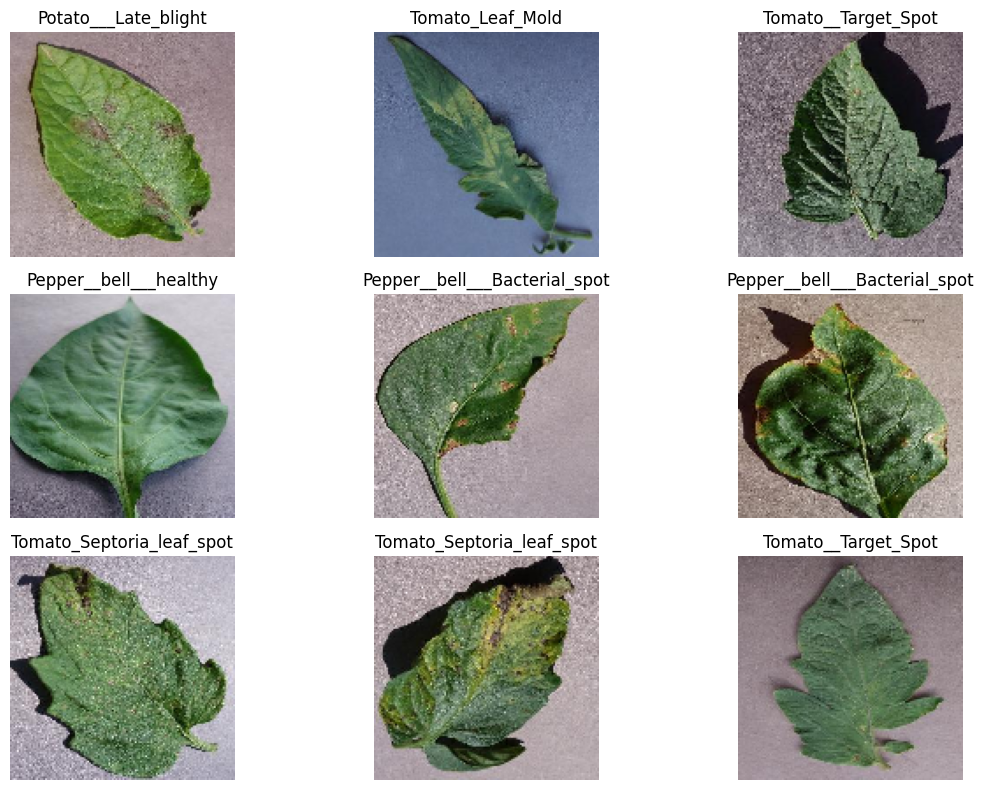

In [14]:
images, labels = next(train_data)

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    plt.title(class_names[np.argmax(labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
model = models.Sequential([

    layers.Conv2D(32, (3, 3), activation='relu',
                  input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.5),

    layers.Dense(len(class_names), activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,575 (12.61 MB)

 Trainable params: 3,306,575 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [18]:
EPOCHS = 15

history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=EPOCHS
)

Epoch 1/15
517/517 ━━━━━━━━━━━━━━━━━━━━ 35s 54ms/step - accuracy: 0.4504 - loss: 1.6931 - val_accuracy: 0.6972 - val_loss: 0.9689
Epoch 2/15
517/517 ━━━━━━━━━━━━━━━━━━━━ 23s 45ms/step - accuracy: 0.6304 - loss: 1.0975 - val_accuracy: 0.7775 - val_loss: 0.6688
Epoch 3/15
517/517 ━━━━━━━━━━━━━━━━━━━━ 25s 49ms/step - accuracy: 0.6941 - loss: 0.8999 - val_accuracy: 0.7943 - val_loss: 0.6300
Epoch 4/15
517/517 ━━━━━━━━━━━━━━━━━━━━ 23s 44ms/step - accuracy: 0.7358 - loss: 0.7742 - val_accuracy: 0.8365 - val_loss: 0.4925
Epoch 5/15
517/517 ━━━━━━━━━━━━━━━━━━━━ 23s 44ms/step - accuracy: 0.7670 - loss: 0.6929 - val_accuracy: 0.8692 - val_loss: 0.4060
Epoch 6/15
517/517 ━━━━━━━━━━━━━━━━━━━━ 23s 44ms/step - accuracy: 0.7843 - loss: 0.6137 - val_accuracy: 0.8741 - val_loss: 0.3983
Epoch 7/15
517/517 ━━━━━━━━━━━━━━━━━━━━ 23s 44ms/step - accuracy: 0.8100 - loss: 0.5489 - val_accuracy: 0.8809 - val_loss: 0.3586
Epoch 8/15
517/517 ━━━━━━━━━━━━━━━━━━━━ 23s 44ms/step - accuracy: 0.8323 - loss: 0.4822 - 

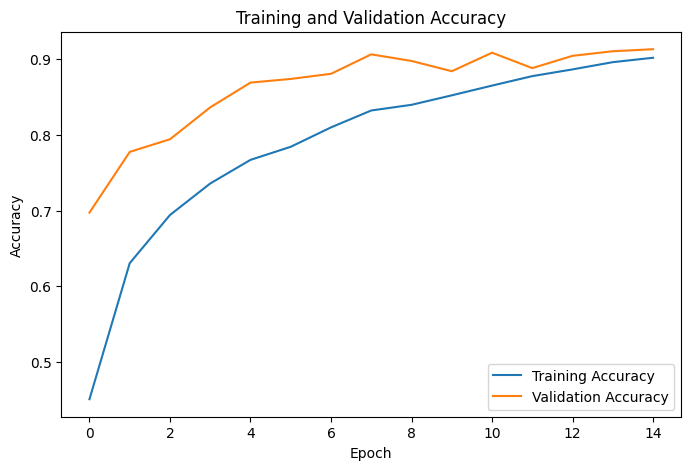

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

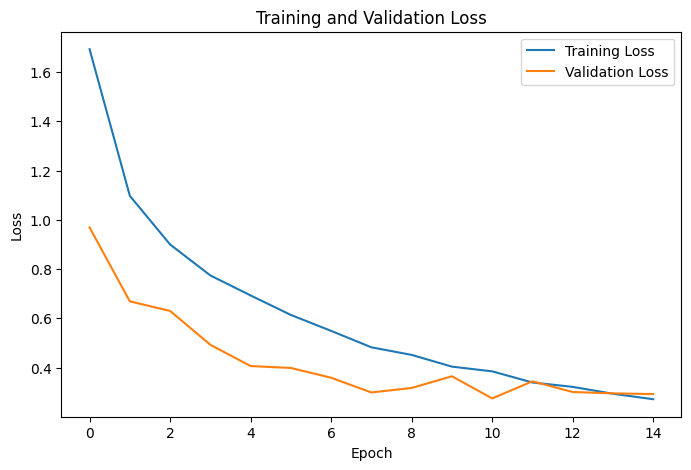

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [21]:
loss, accuracy = model.evaluate(validation_data)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

129/129 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.9134 - loss: 0.2923
Validation Loss: 0.292291522026062
Validation Accuracy: 0.9133915305137634


In [22]:
validation_data.reset()

predictions = model.predict(validation_data)

predicted_classes = np.argmax(predictions, axis=1)
actual_classes = validation_data.classes

129/129 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step


In [23]:
print(classification_report(
    actual_classes,
    predicted_classes,
    target_names=class_names
))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.90      0.90      0.90       199
                     Pepper__bell___healthy       0.94      0.95      0.95       295
                      Potato___Early_blight       0.88      0.96      0.92       200
                       Potato___Late_blight       0.92      0.83      0.87       200
                           Potato___healthy       0.82      0.60      0.69        30
                      Tomato_Bacterial_spot       0.97      0.95      0.96       425
                        Tomato_Early_blight       0.86      0.66      0.75       200
                         Tomato_Late_blight       0.84      0.89      0.87       381
                           Tomato_Leaf_Mold       0.92      0.87      0.89       190
                  Tomato_Septoria_leaf_spot       0.87      0.90      0.88       354
Tomato_Spider_mites_Two_spotted_spider_mite       0.91      0.91

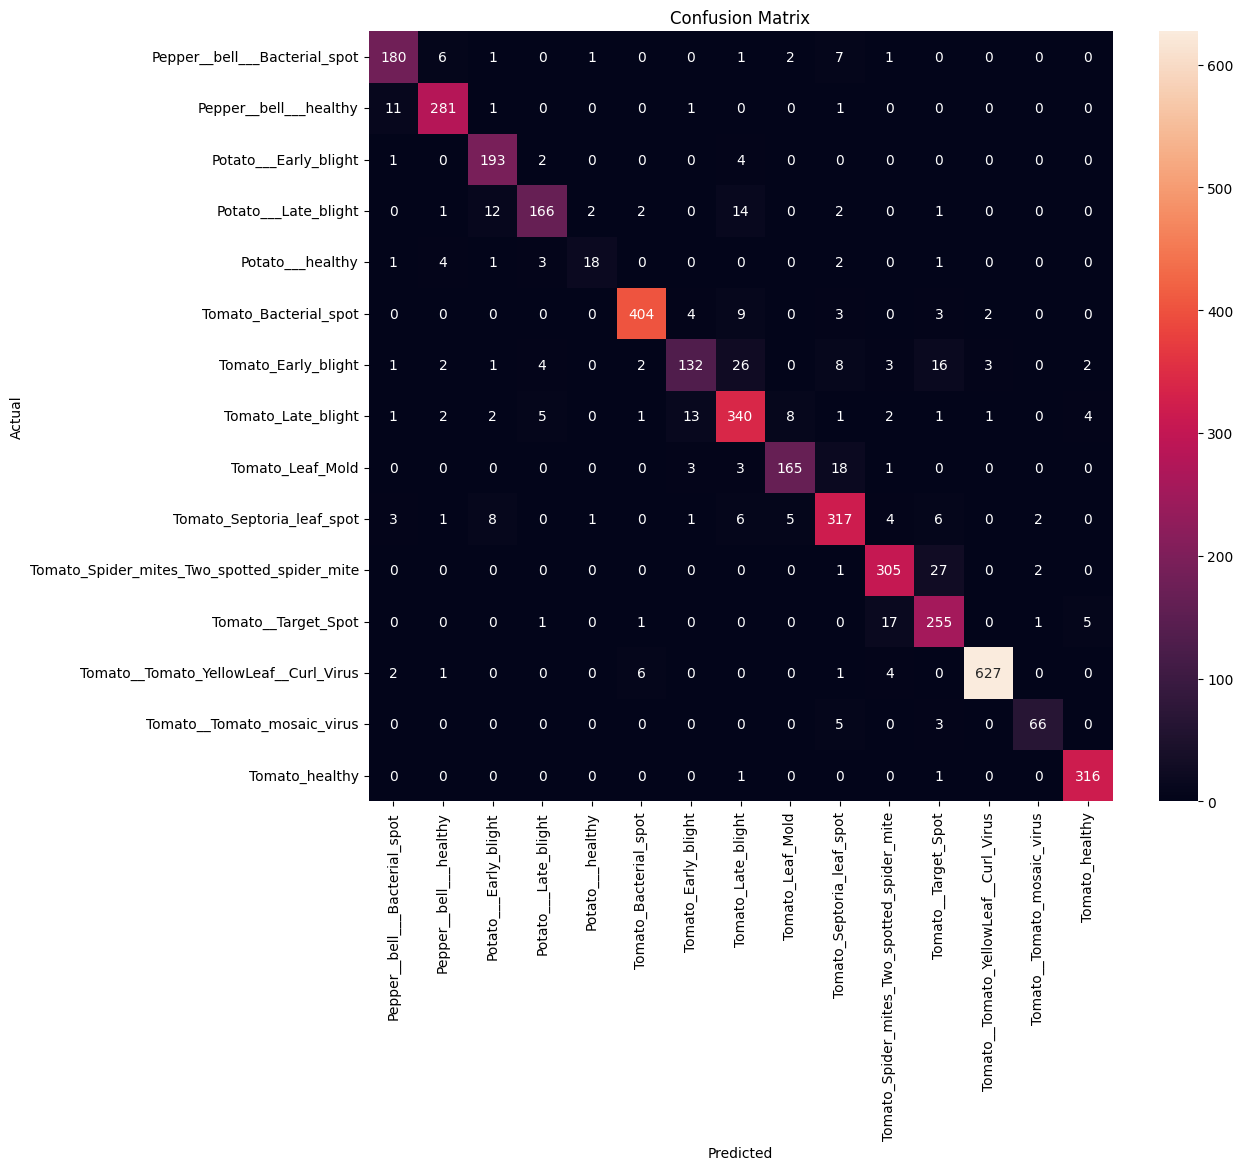

In [24]:
cm = confusion_matrix(
    actual_classes,
    predicted_classes
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.show()

In [25]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle (1).json


In [26]:
from tensorflow.keras.preprocessing import image

filename = list(uploaded.keys())[0]

img = image.load_img(
    filename,
    target_size=(128, 128)
)

img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

predicted_index = np.argmax(prediction)
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

plt.imshow(img)
plt.axis("off")
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Predicted Disease:", predicted_class)
print("Confidence:", f"{confidence:.2f}%")

UnidentifiedImageError: cannot identify image file <_io.BytesIO object at 0x7933905275b0>

In [ ]:
model.save("tomato_disease_cnn.h5")